# Détection de fraude de paiement grâce à une régression logistique

**Contexte du projet** : En tant que Responsable des flux financiers de la Course Croisière EDHEC, je me suis intéressé à la possibilité d'automatiser la détection de fraudes paiement via l'utilisation d'une régression logistique. En effet, lors de l'organisation de nos événements, il m'est arrivé de devoir analyser après coup des vastes bases de données pour retrouver des transactions litigieuses et discuter de leur caractère frauduleux. Ce projet a donc poir  J'ai donc construit ici des variables comportementales ainsi qu'un système de priorisation des alertes afin de retranscrire au mieux les conditions réelles.


**Question** : les données historiques du comportement d'un client et d'un terminal de paiement améliorent-t-elles la détection de fraude, à capacité d'investigation constante ?

**Démarche du projet**

1. Simulation d'un jeu de transactions avec deux types de fraude (vol de carte + vol d'un terminal de paiement).
2. Construction de variables comportementales sans jamais utiliser le futur.
3. Découpage des données dans l'ordre chronologique : entraînement => validation => test.
4. Estimation de deux régressions logistiques : d'abord un modèle **de base** puis un modèle **enrichi**.
5. Comparaison à une règle simple pour 30 alertes par jour.
6. Interprétation des résultats obtenus.


## 1. Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.metrics import precision_recall_curve

## 2. Paramètres de la simulation

J'ai fait le choix de **simuler** les données car, dans un monde simulé **nous connaissons la vérité** (on sait donc quelles transactions sont des fraudes). Cela nous permet de vérifier que la méthode fonctionne.

- `rng` est un générateur aléatoire. La graine `42`(seed) garantit que l'obtention des mêmes chiffres après l'exécution.
- Pérmiètre de la simuation : 2 000 clients, 200 terminaux de paiement, 90 jours d'activité à partir du 1er janvier 2026.

In [2]:
rng = np.random.default_rng(42)

n_customers = 2000
n_terminals = 200
n_days = 90
start = pd.Timestamp("2026-01-01")

## 3. Création du profil des clients

Chaque client $c$ reçoit trois caractéristiques :

- un montant moyen $\mu_c$ tiré e façon uniforme entre 5 € et 100 € : $\mu_c \sim \mathcal{U}(5, 100)$ ;
- un écart-type égal à la moitié de ce montant : $\sigma_c = \mu_c / 2$ ;
- un nombre moyen de transactions par jour $\lambda_c \sim \mathcal{U}(0, 3)$.

Chaque client utilise 5 terminaux « habituels » (`favorite`). C'est un tableau de 2 000 lignes et 5 colonnes : la ligne $c$ contient les numéros des terminaux du client $c$.

Ligne par ligne :
- `pd.DataFrame()` crée un tableau vide ; chaque ligne suivante ajoute une colonne.
- `rng.uniform(a, b, n)` tire `n` nombres uniformes entre `a` et `b`.
- `rng.integers(0, n_terminals, size=(n_customers, 5))` tire des entiers entre 0 et 199.

L'index du tableau (0, 1, …, 1999) sert d'identifiant client.

In [24]:
customers = pd.DataFrame()
customers["mean_amount"] = rng.uniform(5, 100, n_customers)
customers["std_amount"] = customers["mean_amount"] / 2
customers["tx_per_day"] = rng.uniform(0, 3, n_customers)
favorite = rng.integers(0, n_terminals, size=(n_customers, 5))
customers.tail()

,mean_amount,std_amount,tx_per_day
1995,26.383588,13.191794,1.279632
1996,15.006808,7.503404,1.312434
1997,51.513369,25.756684,1.293911
1998,63.151612,31.575806,2.291562
1999,13.298800,6.649400,1.662013


## 4. Génération des transactions légitimes

**Nombre de transactions :** Le nombre de paiements du client $c$ le jour $d$ suit une loi de Poisson de paramètre $\lambda_c$ :

$$P(N_{c,d} = n) = e^{-\lambda_c}\,\frac{\lambda_c^{\,n}}{n!}, \qquad \mathbb{E}[N_{c,d}] = \lambda_c.$$

C'est la loi classique pour compter des événements indépendants sur une période.

La boucle parcourt les 90 jours :
- `rng.poisson(...)` donne pour chaque client son nombre de paiements du jour ;
- `np.repeat(customers.index, n)` répète l'identifiant de chaque client autant de fois qu'il a payé (un client avec 2 paiements apparaît 2 fois) ;
- on range le jour dans un petit tableau, ajouté à la liste `days` ;
- `pd.concat` colle ensuite les 90 tableaux les uns sous les autres.

In [4]:
days = []
for d in range(n_days):
    n = rng.poisson(customers["tx_per_day"])
    ids = np.repeat(customers.index, n)
    days.append(pd.DataFrame({"customer_id": ids, "day": d}))
tx = pd.concat(days, ignore_index=True)
len(tx)

266102

**Caractéristiques de chaque transaction.**

- **Terminal** : un des 5 terminaux habituels du client, choisi au hasard. `favorite[cust, ...]` lit la ligne du client et une colonne tirée entre 0 et 4.
- **Montant** : $a \sim \mathcal{N}(\mu_c, \sigma_c)$. `clip(1, None)` remplace les montants inférieurs à 1 € (car la loi normale peut donner un nombre négatif) par 1 €.
- **Heure** : un nombre de secondes dans la journée $s \sim \mathcal{N}(12\text{h}, 4\text{h})$, ramené entre 0 et 86 399 secondes. Les paiements ont donc lieu surtout en journée, mais environ 7 % ont lieu entre minuit et 6 h.
- `datetime` = date de départ + nombre de jours + nombre de secondes.
- `is_fraud` vaut 0 (transaction supposée légitime) ; `scenario` garde le type de transaction pour l'analyse finale. **Le modèle ne verra jamais la colonne `scenario`.**

`customers["mean_amount"].values[cust]` va chercher, pour chaque transaction, le montant moyen de son client.

In [5]:
n_tx = len(tx)
cust = tx["customer_id"].values
tx["terminal_id"] = favorite[cust, rng.integers(0, 5, n_tx)]

mu = customers["mean_amount"].values[cust]
sd = customers["std_amount"].values[cust]
tx["amount"] = rng.normal(mu, sd).clip(1, None).round(2)

sec = rng.normal(12 * 3600, 4 * 3600, n_tx).clip(0, 86399)
tx["datetime"] = start + pd.to_timedelta(tx["day"], unit="D")
tx["datetime"] += pd.to_timedelta(sec, unit="s")

tx["is_fraud"] = 0
tx["scenario"] = "normal"
tx.head()

,customer_id,day,terminal_id,amount,datetime,is_fraud,scenario
0,0,0,143,50.58,2026-01-01 20:32:16.274134500,0,normal
1,0,0,189,101.56,2026-01-01 08:30:41.555322332,0,normal
2,0,0,143,56.43,2026-01-01 13:21:28.613434227,0,normal
3,2,0,159,75.07,2026-01-01 16:43:34.625649806,0,normal
4,2,0,99,102.43,2026-01-01 17:17:15.360578563,0,normal


## 5. Fraude 1 : carte compromise

Chaque jour $d$, 2 clients ont leur carte compromise pendant 14 jours (du jour $d$ au jour $d+13$). Pendant cette période, chacune de leurs transactions a une probabilité $1/3$ d'être frauduleuse. Le montant frauduleux est alors **multiplié par 5** par rapport au montant normal.

Le montant seul ne suffit pas à détecter cette fraude : 5 × 10 € = 50 €, ce qui est un montant normal pour beaucoup d'autres clients. Il faut **comparer le montant aux habitudes du client**. Le modèle enrichi teste cela.

Ligne par ligne :
- `rng.choice(n_customers, 2, replace=False)` tire 2 clients différents ;
- `target` est un masque vrai/faux : transactions de ces clients pendant les 14 jours ;
- `rng.random(n_tx) < 1/3` est vrai avec une probabilité 1/3 ; on exclut aussi les transactions déjà frauduleuses ;
- `tx.loc[chosen, ...]` modifie seulement les lignes sélectionnées.

In [6]:
for d in range(n_days):
    victims = rng.choice(n_customers, 2, replace=False)
    period = tx["day"].between(d, d + 13)
    target = tx["customer_id"].isin(victims) & period
    chosen = target & (rng.random(n_tx) < 1 / 3)
    chosen = chosen & (tx["is_fraud"] == 0)
    tx.loc[chosen, "amount"] *= 5
    tx.loc[chosen, "is_fraud"] = 1
    tx.loc[chosen, "scenario"] = "carte"

## 6. Fraude 2 : terminal volé

Ce scénario s'inspire des incidents de vol de terminaux de paiement : chaque nuit, un terminal pris au hasard est volé par un fraudeur. Entre minuit et 5 h, il enregistre une **rafale** de 5 à 24 paiements avec des cartes de clients tirés au hasard et des montants entre 20 € et 200 €.

Le **pic d'activité** inhabituel sur ce terminal au cours de **la nuit** rend la fraude potentiellement détectable.


Ligne par ligne :
- `rng.integers(5, 25)` tire la taille de la rafale (entre 5 et 24) ;
- on construit un petit tableau `b` avec les mêmes colonnes que `tx` ;
- `b["terminal_id"] = rng.integers(0, n_terminals)` : un seul terminal pour toute la rafale ;
- à la fin, on colle les rafales à `tx`, puis on **trie par date**. Ce tri est indispensable pour calculer ensuite l'historique.

In [7]:
bursts = []
for d in range(n_days):
    n = rng.integers(5, 25)
    sec = rng.uniform(0, 5 * 3600, n)
    b = pd.DataFrame()
    b["customer_id"] = rng.integers(0, n_customers, n)
    b["day"] = d
    b["terminal_id"] = rng.integers(0, n_terminals)
    b["amount"] = rng.uniform(20, 200, n).round(2)
    b["datetime"] = start + pd.Timedelta(days=d)
    b["datetime"] += pd.to_timedelta(sec, unit="s")
    b["is_fraud"] = 1
    b["scenario"] = "terminal"
    bursts.append(b)

tx = pd.concat([tx] + bursts, ignore_index=True)
tx = tx.sort_values("datetime").reset_index(drop=True)
tx["scenario"].value_counts()

scenario
normal      264885
terminal      1341
carte         1217
Name: count, dtype: int64

**Taux de fraude.** La moyenne d'une variable qui vaut 0 ou 1 est la proportion de 1. On obtient environ 1 % de fraudes 

In [8]:
tx["is_fraud"].mean()

np.float64(0.009564654898426955)

## 7. Première analyse des données

On calcule ici le taux de fraude pour chaque heure de la journée :
- `dt.hour` extrait l'heure de la date ;
- `groupby("hour")["is_fraud"].mean()` donne la proportion de fraudes par heure.

On s'attend à un taux élevé la nuit à cause des terminaux volés. C'est bien le cas comme le montre le graphique ci-dessous.

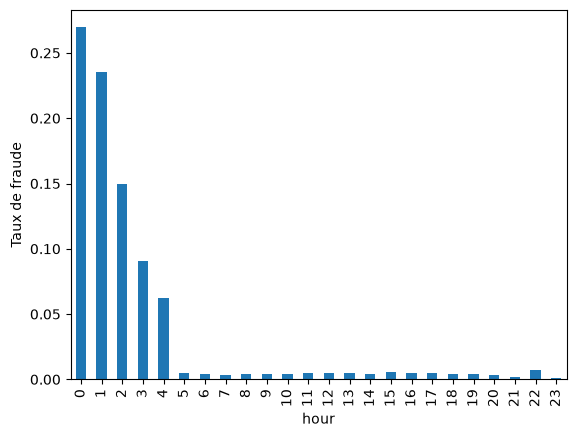

In [9]:
tx["hour"] = tx["datetime"].dt.hour
rate = tx.groupby("hour")["is_fraud"].mean()
rate.plot(kind="bar")
plt.ylabel("Taux de fraude")
plt.show()

## 8. Construction des variables explicatives

**Règle absolue : à l'instant $t$, une variable ne doit utiliser que des informations connues avant $t$.** Sinon le modèle tricherait et ses performances seraint surestimées (**fuite d'information**).

### Variables du modèle de base (la transaction seule)

- `amount` : le montant ;
- `is_night` : 1 si la transaction a lieu entre 0 h et 6 h, 0 sinon.

### Variable 1 du modèle enrichi : écart aux habitudes du client

Montant moyen **passé** du client $c$ avant la transaction $t$ calculé en fonction de ses $n$ transactions précédentes :

$$\bar a_{c,t^-} = \frac{1}{n}\sum_{\ell=1}^{n} a_{c,\ell}.$$

Calculs via le tableau  trié par date :
- `g.cumsum()` donne la somme cumulée des montants du client, **transaction actuelle comprise** ; on retire donc `tx["amount"]` pour garder uniquement le passé ;
- `g.cumcount()` numérote les transactions du client : 0, 1, 2… C'est exactement le nombre $n$ de transactions passées.

On définit alors le **log-ratio** :

$$\text{log\_ratio} = \ln\!\left(\frac{a_t}{\bar a_{c,t^-}}\right).$$

- 0 : montant habituel ; $\ln 5 \approx 1{,}6$ : montant 5 fois supérieur à l'habitude.
- Utilisaton du logarithme car un ratio est asymétrique (×5 donne 5, ÷5 donne 0,2) et peut prendre des valeurs extrêmes. Le log le rend symétrique (+1,6 / −1,6) et réduit l'effet des valeurs extrêmes. Cela convient mieux à un modèle linéaire.
- Pour la toute première transaction d'un client, il n'y a pas d'historique : le calcul donne `NaN` (0/0), remplacé par 0 (« montant habituel ») avec `fillna(0)`.

In [ ]:
tx["is_night"] = (tx["hour"] < 6).astype(int)

g = tx.groupby("customer_id")["amount"]
past_sum = g.cumsum() - tx["amount"]
past_n = g.cumcount()
tx["cust_mean"] = past_sum / past_n
ratio = tx["amount"] / tx["cust_mean"]
tx["log_ratio"] = np.log(ratio).fillna(0)

In [27]:
tx["amount"]

1         37.49
0         34.44
4         27.88
2          8.45
3         35.82
          ...  
267438    29.17
267439     6.70
267440    61.06
267441    46.15
267442    39.42
Name: amount, Length: 267443, dtype: float64

### Variable 2 du modèle enrichi : activité récente du terminal

Nombre de transactions du terminal $j$ dans l'heure qui précède la transaction (sans la compter) :

$$N^{1h}_{j,t} = \#\{\ell : \text{terminal}_\ell = j,\ t - 1\text{h} < t_\ell \le t\} - 1.$$

Ligne par ligne :
- on trie par terminal puis par date ;
- `groupby("terminal_id").rolling("1h", on="datetime")` crée pour chaque terminal une fenêtre glissante d'une heure qui se termine à la transaction actuelle ;
- `["amount"].count()` compte les transactions dans la fenêtre. On retire donc 1 pour ne pas compter la transaction elle-même ;
- `.values` récupère les résultats dans l'ordre du tri, d'où l'importance d'avoir trié juste avant ;
- on retrie enfin par date.

Le tableau compare ensuite la moyenne des variables par scénario : c'est un premier contrôle que les variables portent un signal.

In [11]:
tx = tx.sort_values(["terminal_id", "datetime"])
roll = tx.groupby("terminal_id").rolling("1h", on="datetime")
tx["term_n_1h"] = roll["amount"].count().values - 1
tx = tx.sort_values("datetime")

cols = ["amount", "is_night", "log_ratio", "term_n_1h"]
tx.groupby("scenario")[cols].mean().round(2)

,amount,is_night,log_ratio,term_n_1h
scenario,,,,
carte,279.16,0.07,1.16,1.15
normal,53.01,0.07,-0.23,1.06
terminal,112.02,1.00,0.76,3.05


## 9. Découpage chronologique

On ne mélange jamais les dates au hasard : un modèle de fraude est entraîné sur le passé et utilisé sur le futur. On reproduit cette situation :

| Période | Jours | Rôle |
|---|---|---|
| Entraînement | 0 à 49 | Estimer les coefficients |
| Validation | 50 à 64 | Choisir les réglages (régularisation, pondération) |
| Test | 65 à 89 | Évaluation finale, une seule fois, avec des choix figés |




In [12]:
train = tx[tx["day"] < 50]
valid = tx[(tx["day"] >= 50) & (tx["day"] < 65)]
test = tx[tx["day"] >= 65]

for name, data in [("train", train), ("valid", valid), ("test", test)]:
    print(name, len(data), data["is_fraud"].sum())

train 149074 1371
valid 44513 418
test 73856 769


## 10. Implémentation de la régression logistique

### Le modèle

On note $x_i$ le vecteur des variables de la transaction $i$ et $y_i \in \{0, 1\}$ son étiquette. On combine linéairement les variables :

$$z_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip},$$

puis on transforme ce nombre en probabilité avec la **fonction logistique** (sigmoïde) :

$$p_i = P(y_i = 1 \mid x_i) = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}.$$

$\sigma$ envoie n'importe quel réel dans $]0, 1[$ : $\sigma(0) = 0{,}5$, $\sigma(z) \to 1$ quand $z \to +\infty$.

Forme équivalente, en **log-cote** (log-odds) :

$$\ln\!\left(\frac{p_i}{1 - p_i}\right) = \beta_0 + \beta^\top x_i.$$

Le modèle est donc linéaire, non pas dans la probabilité, mais dans le logarithme de la cote.

### L'estimation : maximum de vraisemblance

On cherche les $\beta$ qui rendent les étiquettes observées les plus probables. Cela revient à minimiser la **log-loss** (entropie croisée) :

$$\mathcal{L}(\beta) = -\sum_{i=1}^{n}\Big[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Big].$$

Si $y_i = 1$, on pénalise $-\ln p_i$ : grand si le modèle donne une faible probabilité à une vraie fraude. Il n'existe pas de formule fermée comme pour les moindres carrés : scikit-learn utilise un algorithme d'optimisation numérique.

### La régularisation L2

On ajoute une pénalité sur la taille des coefficients :

$$\min_\beta\ \mathcal{L}(\beta) + \frac{1}{2C}\,\|\beta\|_2^2.$$

Dans scikit-learn, `C` est **l'inverse** de la force de régularisation : petit `C` = coefficients plus fortement ramenés vers 0 = modèle plus prudent.

### La standardisation

Chaque variable est transformée en $\tilde x = (x - \text{moyenne}) / \text{écart-type}$, calculés sur l'entraînement. Deux raisons l'expliquent : la pénalité traite toutes les variables de la même manière (sinon elle dépendrait de leurs unités) et les coefficients deviennent comparables entre eux.

### La pondération des classes

Avec `class_weight="balanced"`, chaque classe $k$ reçoit un poids $w_k = \dfrac{n}{2\,n_k}$ dans la log-loss : les rares fraudes comptent beaucoup plus. Mais ce n'est pas automatiquement meilleur. Nous le testerons en validation.

Voici à quoi ressemble la sigmoïde :

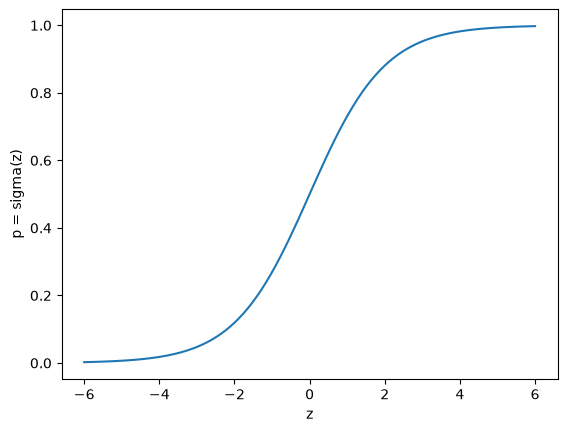

In [13]:
z = np.linspace(-6, 6, 100)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.xlabel("z")
plt.ylabel("p = sigma(z)")
plt.show()

### Comparaison des deux modèles

- **Base** : `amount`, `is_night` (la transaction seule).
- **Enrichi** : les mêmes + `log_ratio`, `term_n_1h` (l'historique).

La fonction `fit_model` :
- crée une régression logistique avec un `C` donné et une pondération éventuelle (`balanced=True` ou `False`) ;
- l'enchaîne après la standardisation avec `make_pipeline` ;
- l'estime avec `fit(X, y)`.

Ensuite, `model.predict_proba(X)[:, 1]` renvoie la probabilité estimée de fraude (la colonne 1 correspond à la classe « fraude »).

In [14]:
base = ["amount", "is_night"]
enriched = base + ["log_ratio", "term_n_1h"]

def fit_model(data, cols, C=1.0, balanced=False):
    weight = "balanced" if balanced else None
    logit = LogisticRegression(C=C, class_weight=weight)
    model = make_pipeline(StandardScaler(), logit)
    model.fit(data[cols], data["is_fraud"])
    return model

## 11. Choix des métriques d'évaluation



Avec $TP$ = fraudes alertées, $FP$ = transactions légitimes alertées (fausses alertes), $FN$ = fraudes manquées, on a deux métriques pertinentes :

$$\text{Précision} = \frac{TP}{TP + FP}, \qquad \text{Rappel} = \frac{TP}{TP + FN}.$$

- Précision : parmi les alertes, quelle part de vraies fraudes ?
- Rappel : parmi les fraudes, quelle part est réllement détectée ?

**Average Precision (AP).** On classe les transactions du score le plus élevé au plus faible et on fait varier le seuil d'alerte. On obtient alors des couples (rappel $R_n$, précision $P_n$)tq :

$$AP = \sum_n (R_n - R_{n-1})\,P_n.$$

C'est une moyenne des précisions, pondérée par les gains de rappel. Un score aléatoire donne une AP proche du taux de fraude (environ 0,01) tandis qu'un score parfait donne 1.

**Précision@k** : Elle représente la contrainte opérationnelle. Une équipe ne peut examiner que $k$ alertes par jour. Chaque jour, on prend les $k$ transactions au score le plus élevé :

$$\text{Précision@}k = \frac{\text{fraudes parmi les alertes}}{\text{nombre d'alertes}}.$$

On calcule aussi le **rappel@k** : la part de toutes les fraudes de la période qui tombent dans ces alertes. On fixe $k = 30$ ce qui est proche du nombre moyen de fraudes par jour.

La fonction `top_k` :
- copie les colonnes utiles et ajoute le score ;
- trie par score décroissant ;
- `groupby("day").head(k)` garde les $k$ premières lignes de **chaque jour**.

In [15]:
def top_k(data, scores, k=30):
    d = data[["day", "is_fraud", "scenario"]].copy()
    d["score"] = scores
    d = d.sort_values("score", ascending=False)
    return d.groupby("day").head(k)

## 12. Choix des réglages sur la validation

On teste 4 valeurs de `C` et 2 options de pondération, pour chacun des deux modèles (16 combinaisons). Pour chacune :
1. estimation sur l'entraînement ;
2. probabilités sur la validation ;
3. calcul de l'AP.

Le test n'est pas utilisé ici car si on choisissait les réglages en regardant le test, son score final serait trop optimiste.

`res.groupby("modele")["AP"].idxmax()` donne, pour chaque modèle, la ligne de meilleure AP.

In [16]:
res = []
for name, cols in [("base", base), ("enrichi", enriched)]:
    for C in [0.01, 0.1, 1, 10]:
        for balanced in [False, True]:
            m = fit_model(train, cols, C, balanced)
            p = m.predict_proba(valid[cols])[:, 1]
            ap = average_precision_score(valid["is_fraud"], p)
            res.append([name, C, balanced, ap])

res = pd.DataFrame(res, columns=["modele", "C", "balanced", "AP"])
res.round(3)

,modele,C,balanced,AP
0,base,0.01,False,0.505
1,base,0.01,True,0.491
2,base,0.10,False,0.506
3,base,0.10,True,0.491
4,base,1.00,False,0.506
5,base,1.00,True,0.491
6,base,10.00,False,0.506
7,base,10.00,True,0.491
8,enrichi,0.01,False,0.684
9,enrichi,0.01,True,0.655


In [17]:
best = res.loc[res.groupby("modele")["AP"].idxmax()]
best = best.set_index("modele")
best

,C,balanced,AP
modele,,,
base,10.0,False,0.506201
enrichi,10.0,False,0.688559


**Conclusion :.** La valeur de `C` change très peu le résultat : avec plus de 100 000 observations et seulement 2 à 4 variables, le risque de surapprentissage est faible et la pénalité a peu d'effet. La pondération `balanced` dégrade un peu l'AP : elle augmente les probabilités de fraude, mais ne classe pas mieux les transactions.

## 13. Évaluation finale sur le test

On estime les deux modèles sur l'entraînement avec les réglages retenus puis on les évalue **une seule fois** sur le test. On ajoute égalemet une **règle simple** de référence : classer les transactions par montant (le score est le montant lui-même).

Pour chaque méthode, on calcule l'AP, la précision@30 et le rappel@30.

In [18]:
b = best.loc["base"]
e = best.loc["enrichi"]
m_base = fit_model(train, base, b["C"], b["balanced"])
m_enr = fit_model(train, enriched, e["C"], e["balanced"])

scores = {
    "regle montant": test["amount"],
    "logit base": m_base.predict_proba(test[base])[:, 1],
    "logit enrichi": m_enr.predict_proba(test[enriched])[:, 1],
}

rows = []
for name, s in scores.items():
    top = top_k(test, s)
    ap = average_precision_score(test["is_fraud"], s)
    prec = top["is_fraud"].mean()
    rec = top["is_fraud"].sum() / test["is_fraud"].sum()
    rows.append([name, ap, prec, rec])

cols_res = ["methode", "AP", "precision@30", "rappel@30"]
pd.DataFrame(rows, columns=cols_res).round(3)

,methode,AP,precision@30,rappel@30
0,regle montant,0.356,0.360,0.351
1,logit base,0.495,0.472,0.460
2,logit enrichi,0.696,0.648,0.632


## 14. Courbes précision–rappel

La courbe ci-dessous renvoie la précision et le rappel pour tous les seuils possibles. Chaque courbe montre le compromis : plus on lance d'alertes, plus le rappel monte, mais plus la précision baisse. Une courbe plus haute et plus décalée vers ma droite est meilleure. L'Average Precision résume cette courbe.

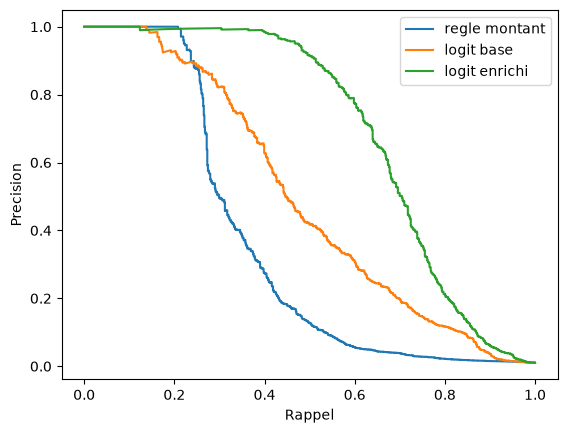

In [19]:
for name, s in scores.items():
    prec, rec, _ = precision_recall_curve(test["is_fraud"], s)
    plt.plot(rec, prec, label=name)
plt.xlabel("Rappel")
plt.ylabel("Precision")
plt.legend()
plt.show()

## 15. Interprétation des coefficients

`m_enr[-1]` est la dernière étape du pipeline, c'est-à-dire la régression logistique ; `coef_[0]` contient ses $\beta$.

$\beta_j$ représente l'effet d'une hausse d'**un écart-type** de la variable $j$ sur la log-cote. On obtient alors en passant à l'exponentielle :

$$\frac{\text{cote}(x_j + 1)}{\text{cote}(x_j)} = e^{\beta_j}.$$

C'est l'**odds ratio** : par exemple, $e^{\beta} = 3$ signifie que la cote de fraude est multipliée par 3 quand la variable augmente d'un écart-type, **à autres variables fixées**.


In [20]:
coefs = pd.DataFrame()
coefs["variable"] = enriched
coefs["beta"] = m_enr[-1].coef_[0]
coefs["odds_ratio"] = np.exp(coefs["beta"])
coefs.round(3)

,variable,beta,odds_ratio
0,amount,1.062,2.892
1,is_night,1.054,2.869
2,log_ratio,1.266,3.548
3,term_n_1h,0.869,2.385


## 16. Analyse des erreurs

Un score global ne suffit pas. L'enjeu est de savoir quelles fraudes sont détectées et pourquoi certaines sont manquées.

**a) Rappel@30 par type de fraude.** `value_counts()` compte les fraudes alertées par scénario. On divise donc par le nombre total de fraudes de chaque scénario.

In [21]:
top = top_k(test, scores["logit enrichi"])
found = top[top["is_fraud"] == 1]["scenario"].value_counts()
total = test[test["is_fraud"] == 1]["scenario"].value_counts()
(found / total).round(3)

scenario
terminal    0.738
carte       0.526
Name: count, dtype: float64

**b) Fraudes « carte » détectées ou manquées.** `cartes.index.isin(top.index)` est vrai pour les fraudes de carte qui figurent dans les alertes. On compare la moyenne des variables dans les deux groupes. `~` inverse le masque (vrai devient faux).

In [22]:
cartes = test[test["scenario"] == "carte"]
alerted = cartes.index.isin(top.index)
cmp = pd.DataFrame()
cmp["detectees"] = cartes[alerted][cols].mean()
cmp["manquees"] = cartes[~alerted][cols].mean()
cmp.round(2)

,detectees,manquees
amount,395.30,100.26
is_night,0.10,0.05
log_ratio,1.68,0.83
term_n_1h,1.23,1.05


**c) Les fausses alertes.** Ce sont les transactions légitimes qui ont pris une place dans le budget d'alertes. On regarde leurs variables.

In [23]:
fp = top[top["is_fraud"] == 0]
test.loc[fp.index, cols].describe().round(2)

,amount,is_night,log_ratio,term_n_1h
count,264.00,264.00,264.00,264.00
mean,153.60,0.78,0.56,1.38
std,36.78,0.41,0.20,1.84
min,44.96,0.00,0.01,0.00
25%,130.71,1.00,0.43,0.00
50%,150.97,1.00,0.58,1.00
75%,174.46,1.00,0.70,2.00
max,253.65,1.00,1.13,9.00


## 17. Conclusions et limites

**Résultat principal (graine 42).** À budget égal de 30 alertes par jour sur la période de test, on a les résultats suivants :

| Méthode | AP | Précision@30 | Rappel@30 |
|---|---|---|---|
| Règle du montant | 0,356 | 36,0 % | 35,1 % |
| Logit de base | 0,495 | 47,2 % | 46,0 % |
| Logit enrichi | 0,696 | 64,8 % | 63,2 % |

L'historique apporte donc une information que la transaction seule ne contient pas : environ 17 points de **précision@30** en plus pour le même nombre d'alertes entre la reg log de base et celle enrichie. À noter que ces chiffres sont ceux de notre simulation et non pas une performance attendue sur données réelles.

**Ce que montrent les erreurs.**
- Environ 74 % des fraudes « terminal volé » sont alertées, grâce à la combinaison « nuit » + « activité récente du terminal ». Les petites rafales (5 à 7 paiements étalés sur la nuit) sont toutefois un peu moins bien détectées (environ deux tiers de leurs paiements sont alertés, contre environ 80 % pour les plus grosses).
- Seulement environ 53 % des fraudes « carte » sont alertées. Les fraudes manquées ont un montant moyen d'environ 100 € contre 395 € pour les détectées, et un log-ratio deux fois plus faible : un montant multiplié par 5 chez un petit payeur reste un petit montant. De plus, la moyenne passée du client est elle-même gonflée par les fraudes précédentes de la période de compromission, ce qui réduit le log-ratio.
- Les fausses alertes sont surtout des transactions légitimes **de nuit** avec un montant assez élevé (environ 150 € en moyenne, 78 % de nuit) : le modèle a appris que « nuit » est suspect, ce qui pénalise en réalité les clients qui paient réellement la nuit.

**Limites du modèle**
- Les données sont **simulées** et les fraudes suivent des règles que nous avons choisies (la nuit, multiplication par 5) : les performances ne prouvent donc rien sur des données réelles.
- Le modèle est linéaire dans la log-cote : il ne capte pas d'interactions (par exemple « nuit **et** pic d'activité ») sauf si on les crée à la main.
- Un seul découpage temporel : pas encore de mesure de l'incertitude des écarts entre modèles.
- Pas de calibration des probabilités vérifiée => nous utilisons surtout le score pour **classer**.
